# Sumativa 3 | Modelamiento e integración S1 → S2 → S3

**Universidad Andrés Bello · Magíster en Ciencia de Datos e Inteligencia Artificial**  
**Estadística Computacional (MCDI501) · Grupo 7 · Octubre de 2026**  
Felipe Palma Barrientos · Vicente Aguila Rojas · Cristian Grandon Grandon · Jorge Gutierrez Jaramillo

**Proyecto:** Predicción de atrasos en envíos de comercio electrónico.  
**Variable objetivo:** `Reached.on.Time_Y.N` (`1` = atrasado, `0` = a tiempo).  
**Propósito:** Comparar estrategias de tratamiento de valores faltantes, construir tres modelos logísticos, diagnosticar el mejor, evaluar su estabilidad mediante bootstrap y fundamentar decisiones operativas.

**Fuentes trazables:** `notebooks/sumativa_1.ipynb`, `notebooks/sumativa_2.ipynb`, `data/raw/customer_analytics.csv`, `data/processed/ecommerce_mcar.csv`, `data/processed/resultados_validos_s2.json` y materiales Semana 3.

> **Nota metodológica:** La generación de valores faltantes MCAR (10% en costo y peso) corresponde a una intervención didáctica realizada en S1. Los modelos de imputación se ajustan exclusivamente con observaciones completas del conjunto de entrenamiento, sin utilizar los valores originales ocultados. Estos últimos se recuperan únicamente para evaluar la calidad de las imputaciones mediante RMSE y MAE, y fundamentar la selección provisional de la estrategia de tratamiento de faltantes.
>
> El conjunto de prueba se mantiene separado de los procesos de ajuste, imputación, escalado y selección de modelos. Las tres estrategias de tratamiento de faltantes se compararán sobre un mismo conjunto de prueba con predictores completos, con el propósito de garantizar la comparabilidad de los resultados y evitar fugas de información.

## 1. Configuración, lectura y controles de integridad
Ejecutar desde la carpeta `notebooks/` o desde la raíz del repositorio. Dependencias adicionales: `scikit-learn`, `statsmodels`.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay
from sklearn.base import clone
SEED=42; rng=np.random.default_rng(SEED)
ROOT=next((p for p in [Path.cwd(),Path.cwd().parent] if (p/'data/processed/ecommerce_mcar.csv').exists()),None)
if ROOT is None: raise FileNotFoundError('Abrir notebook desde raíz o notebooks/ del repositorio')
df=pd.read_csv(ROOT/'data/processed/ecommerce_mcar.csv')
with open(ROOT/'data/processed/resultados_validos_s2.json',encoding='utf-8') as f: s2=json.load(f)
TARGET='Reached.on.Time_Y.N'; MISS=['Cost_of_the_Product','Weight_in_gms']
assert len(df)==10999 and df[TARGET].notna().all()
assert all(df[c].isna().sum()==1100 for c in MISS)
assert set(df[TARGET].unique())=={0,1}
print('Datos:',df.shape,' | Faltantes:',df[MISS].isna().sum().to_dict())
print('S2 relaciones:',[(x['relacion'],round(x['rho_s1'],3),x['incluye_cero']) for x in s2['correlaciones']])

Datos: (10999, 12)  | Faltantes: {'Cost_of_the_Product': 1100, 'Weight_in_gms': 1100}
S2 relaciones: [('Peso y descuento', -0.318, False), ('Llamadas y costo', 0.293, False), ('Valoración y peso', -0.01, True)]


## 2. Evidencia S1/S2 para decisiones de modelamiento
En S1 el archivo original no tenía faltantes; se introdujeron **1.100 (10%) en costo y 1.100 (10%) en peso**, bajo un mecanismo artificial MCAR. En S2 se verificó estabilidad bootstrap de **peso–descuento** (ρ≈−0,318) y **llamadas–costo** (ρ≈0,293), mientras **valoración–peso** no presentó signo concluyente. Esto orienta las variables predictoras de imputación, **sin confundir correlación entre predictores con capacidad predictiva del atraso**. S2 tampoco confirmó una asociación entre transporte y puntualidad; se mantiene transporte como candidato de contraste, no como predictor demostrado.

Se excluye `ID` por ser identificador. La selección se realiza solo sobre entrenamiento. No se utiliza el target para imputar, para evitar contaminación entre clases y preservar un uso predictivo legítimo.

In [2]:
print(pd.DataFrame({'faltantes':df.isna().sum(),'porcentaje':100*df.isna().mean()}).query('faltantes>0').round(2))
print(pd.DataFrame(s2['correlaciones'])[['relacion','rho_s1','ic_inf','ic_sup','incluye_cero']].round(3))
features=[c for c in df if c not in [TARGET,'ID']]
X=df[features].copy(); y=df[TARGET].astype(int)
idx_train,idx_test=train_test_split(np.arange(len(df)),test_size=.30,random_state=SEED,stratify=y)
# Test común: solo observaciones completas en los predictores afectados por MCAR.
idx_test=idx_test[X.iloc[idx_test][MISS].notna().all(axis=1).to_numpy()]
Xtr,Xte=X.iloc[idx_train].copy(),X.iloc[idx_test].copy(); ytr,yte=y.iloc[idx_train],y.iloc[idx_test]
print('Train:',len(Xtr),'Test común completo:',len(Xte),'Prevalencia test:',round(yte.mean(),4))

                     faltantes  porcentaje
Cost_of_the_Product       1100        10.0
Weight_in_gms             1100        10.0
            relacion  rho_s1  ic_inf  ic_sup  incluye_cero
0   Peso y descuento  -0.318  -0.336  -0.299         False
1   Llamadas y costo   0.293   0.273   0.313         False
2  Valoración y peso  -0.010  -0.030   0.009          True
Train: 7699 Test común completo: 2691 Prevalencia test: 0.5953


## 3. Imputación por regresión lineal múltiple (entrenamiento únicamente)

Se implementan dos modelos de regresión lineal múltiple para estimar los valores faltantes de `Cost_of_the_Product` y `Weight_in_gms`, utilizando cuatro variables predictoras en cada caso.

La selección considera los antecedentes de S1 y S2, particularmente las asociaciones entre llamadas de atención al cliente y costo del producto, y entre peso y descuento ofrecido, cuya estabilidad fue evaluada mediante bootstrap. Se incorporan adicionalmente otras variables como candidatas predictivas, cuya utilidad se contrasta mediante indicadores de ajuste y errores de validación, sin asumir que todas las relaciones fueron confirmadas en S2.

Los modelos se ajustan exclusivamente con observaciones completas del conjunto de entrenamiento. Para los registros que presentan valores faltantes simultáneamente en peso y costo, se realiza una inicialización mediante medianas y dos pasadas de actualización por regresión.

Se utiliza una imputación determinista, reconociendo sus posibles efectos sobre la variabilidad de las distribuciones originales. El conjunto de prueba no participa en la estimación de los coeficientes ni de las medianas.

In [3]:
IMP_PRED={'Cost_of_the_Product':['Customer_care_calls','Prior_purchases','Discount_offered','Weight_in_gms'],
          'Weight_in_gms':['Discount_offered','Cost_of_the_Product','Customer_care_calls','Prior_purchases']}
models_imp={}; imp_stats=[]
for target,preds in IMP_PRED.items():
    observed=Xtr[[target]+preds].dropna()
    fit=sm.OLS(observed[target],sm.add_constant(observed[preds],has_constant='add')).fit(cov_type='HC3')
    models_imp[target]=fit
    resid=fit.resid
    imp_stats.append({'variable':target,'n_completos':len(observed),'R2_ajustado':fit.rsquared_adj,'RMSE_entrenamiento':np.sqrt(np.mean(resid**2)),'p_Breusch_Pagan':__import__('statsmodels.stats.diagnostic',fromlist=['het_breuschpagan']).het_breuschpagan(fit.resid,fit.model.exog)[1]})
    print('\n',target,'\n',fit.summary().tables[1])
print(pd.DataFrame(imp_stats).round(4))
def regression_impute(frame):
    d=frame.copy()
    missing={v:d[v].isna().to_numpy() for v in MISS}
    for v in MISS:d[v]=d[v].fillna(Xtr[v].median())
    for _ in range(2):
        for v,preds in IMP_PRED.items():
            if missing[v].any():
                pred=models_imp[v].predict(sm.add_constant(d.loc[missing[v],preds],has_constant='add'))
                # Los pesos y costos deben ser positivos; truncamiento explícito.
                d.loc[missing[v],v]=np.maximum(pred,1)
    return d
Xreg=regression_impute(Xtr)
Xsimple=Xtr.copy()
for v in MISS:Xsimple[v]=Xsimple[v].fillna(Xtr[v].median())
complete_mask=Xtr[MISS].notna().all(axis=1)
Xdel=Xtr.loc[complete_mask]; ydel=ytr.loc[complete_mask]
assert not Xreg.isna().any().any() and not Xsimple.isna().any().any()
print('Imputados por regresión:',Xtr[MISS].isna().sum().to_dict())


 Cost_of_the_Product 
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 174.7616      3.897     44.844      0.000     167.123     182.400
Customer_care_calls    11.2568      0.564     19.970      0.000      10.152      12.362
Prior_purchases         1.6422      0.408      4.020      0.000       0.842       2.443
Discount_offered       -0.3920      0.042     -9.427      0.000      -0.474      -0.311
Weight_in_gms          -0.0030      0.000     -7.174      0.000      -0.004      -0.002

 Weight_in_gms 
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                6966.1428    104.953     66.374      0.000    6760.438    7171.848
Discount_offered      -44.1538      0.976    -45.240      0.000     -46.067     

### 3.1. Evaluación de imputación y comparación descriptiva

Se realiza una primera evaluación de la capacidad predictiva de los modelos mediante una partición de observaciones completas del conjunto de entrenamiento (80% para ajuste y 20% para validación).

Se comparan las imputaciones por regresión y mediana utilizando RMSE y MAE, complementando estos resultados con el análisis de medias, desviaciones estándar y correlaciones de Spearman bajo las tres estrategias de tratamiento de valores faltantes.

Esta validación preliminar se complementa posteriormente con una evaluación directa sobre los valores ocultados mediante MCAR en S1, descrita en la sección 3.3.

In [4]:
for v,preds in IMP_PRED.items():
    obs=Xtr[[v]+preds].dropna()
    a,b=train_test_split(obs.index,test_size=.20,random_state=SEED)
    f=LinearRegression().fit(obs.loc[a,preds],obs.loc[a,v]); pred=f.predict(obs.loc[b,preds])
    baseline=np.repeat(obs.loc[a,v].median(),len(b))
    print(
    v,
    'RMSE regresión:', round(np.sqrt(np.mean((pred - obs.loc[b, v])**2)), 2),
    'RMSE mediana:', round(np.sqrt(np.mean((baseline - obs.loc[b, v])**2)), 2),
    'MAE regresión:', round(np.mean(np.abs(pred - obs.loc[b, v])), 2),
    'MAE mediana:', round(np.mean(np.abs(baseline - obs.loc[b, v])), 2)
)
frames={'eliminacion':Xdel,'mediana':Xsimple,'regresion':Xreg}
rows=[]
for name,d in frames.items():
    for v in MISS:
        rows.append({'estrategia':name,'variable':v,'n':len(d),'media':d[v].mean(),'desv':d[v].std(),
                     'rho_peso_descuento':d['Weight_in_gms'].corr(d['Discount_offered'],method='spearman'),
                     'rho_llamadas_costo':d['Customer_care_calls'].corr(d['Cost_of_the_Product'],method='spearman')})
comparison=pd.DataFrame(rows)
print(comparison.round(3).to_string(index=False))

Cost_of_the_Product RMSE regresión: 45.3 RMSE mediana: 48.16 MAE regresión: 37.91 MAE mediana: 41.3
Weight_in_gms RMSE regresión: 1423.05 RMSE mediana: 1739.77 MAE regresión: 1194.39 MAE mediana: 1450.44
 estrategia            variable    n    media     desv  rho_peso_descuento  rho_llamadas_costo
eliminacion Cost_of_the_Product 6219  209.881   48.027              -0.322               0.289
eliminacion       Weight_in_gms 6219 3630.433 1630.123              -0.322               0.289
    mediana Cost_of_the_Product 7699  210.576   45.362              -0.325               0.270
    mediana       Weight_in_gms 7699 3684.592 1554.683              -0.325               0.270
  regresion Cost_of_the_Product 7699  210.203   45.653              -0.335               0.304
  regresion       Weight_in_gms 7699 3632.460 1571.429              -0.335               0.304


### 3.2. Diagnóstico de los modelos de regresión utilizados para imputación

Antes de seleccionar la estrategia de tratamiento de valores faltantes, se evalúa el comportamiento de los dos modelos de regresión lineal múltiple ajustados sobre observaciones completas del conjunto de entrenamiento.

El diagnóstico considera la relación entre valores predichos y residuos, así como la distribución de estos últimos mediante gráficos Q-Q. Estas evaluaciones complementan los indicadores de ajuste (R² ajustado y RMSE) y la prueba de Breusch-Pagan realizada anteriormente.

El objetivo es identificar posibles patrones de heterocedasticidad, desviaciones de normalidad y errores sistemáticos que puedan afectar la calidad de las imputaciones. Los resultados permitirán documentar las limitaciones de los modelos antes de utilizarlos en el análisis de clasificación.

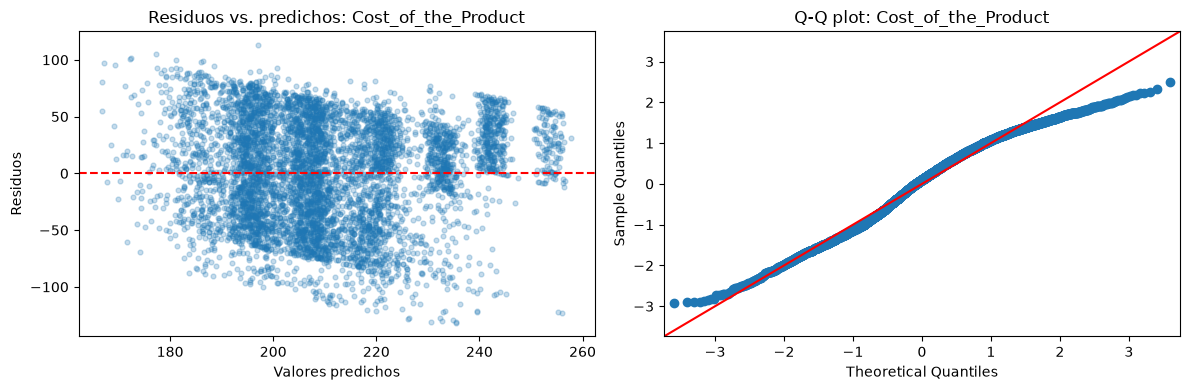


Variable: Cost_of_the_Product
R² ajustado: 0.1224
RMSE entrenamiento: 44.97
Media de residuos: 0.0000


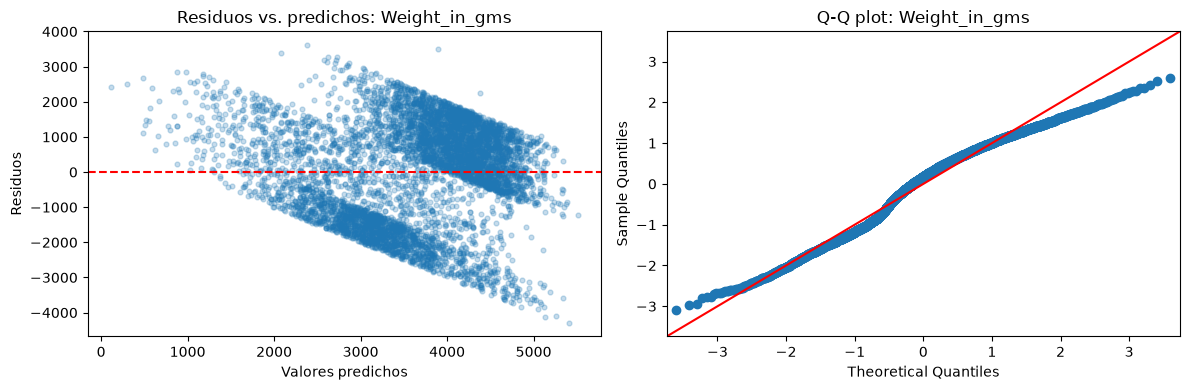


Variable: Weight_in_gms
R² ajustado: 0.2721
RMSE entrenamiento: 1390.22
Media de residuos: -0.0000


In [5]:
# ============================================================
# Diagnóstico de los modelos de regresión para imputación
# ============================================================

import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np
import pandas as pd

for variable, modelo in models_imp.items():

    predichos = modelo.fittedvalues
    residuos = modelo.resid

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Gráfico 1: Residuos frente a valores predichos
    axes[0].scatter(
        predichos,
        residuos,
        alpha=0.25,
        s=12
    )

    axes[0].axhline(0, color="red", linestyle="--")

    axes[0].set_title(f"Residuos vs. predichos: {variable}")
    axes[0].set_xlabel("Valores predichos")
    axes[0].set_ylabel("Residuos")

    # Gráfico 2: Q-Q plot
    sm.qqplot(
        residuos,
        line="45",
        fit=True,
        ax=axes[1]
    )

    axes[1].set_title(f"Q-Q plot: {variable}")

    plt.tight_layout()
    plt.show()

    # Resumen de diagnóstico
    print(f"\nVariable: {variable}")
    print(f"R² ajustado: {modelo.rsquared_adj:.4f}")
    print(f"RMSE entrenamiento: {np.sqrt(np.mean(residuos**2)):.2f}")
    print(f"Media de residuos: {residuos.mean():.4f}")

### 3.3. Validación de imputaciones utilizando los valores originales de S1

Con el propósito de evaluar la calidad de las estrategias de imputación, se recupera el conjunto de datos original utilizado en la Sumativa 1, previo a la generación artificial de valores faltantes bajo un mecanismo MCAR.

A través del identificador único `ID`, se vinculan los registros originales con el conjunto de entrenamiento utilizado en S3. Esto permite recuperar los valores verdaderos de `Cost_of_the_Product` y `Weight_in_gms` que fueron ocultados durante S1.

La validación compara dos estrategias: imputación simple mediante mediana e imputación mediante regresión lineal múltiple. Para cada variable se calculan el error cuadrático medio en su raíz (RMSE) y el error absoluto medio (MAE), considerando exclusivamente las observaciones que presentaban valores faltantes en el conjunto modificado.

Adicionalmente, se distinguen tres escenarios: registros con costo faltante, registros con peso faltante y registros donde ambas variables presentan valores faltantes simultáneamente.

Este procedimiento permite evaluar directamente la capacidad de recuperación de los métodos de imputación sobre los valores ocultados en S1, sin generar nuevos faltantes artificiales. Los valores originales se utilizan exclusivamente para validación y no participan en el ajuste de los modelos de imputación.

Los resultados servirán para fundamentar la estrategia de tratamiento de valores faltantes seleccionada para el desarrollo de los modelos de regresión logística.

In [6]:
# ============================================================
# VALIDACIÓN DE IMPUTACIONES CON VALORES ORIGINALES DE S1
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Recuperar el dataset original de S1
ruta_original = ROOT / "data" / "raw" / "customer_analytics.csv"

df_original = pd.read_csv(ruta_original)

# 2. Verificar identificadores únicos
assert df_original["ID"].is_unique, "Existen ID duplicados en el original."
assert df["ID"].is_unique, "Existen ID duplicados en el dataset MCAR."

# 3. Vincular los registros por ID
# Se conserva el orden y los índices de Xtr.
ids_train = df.loc[Xtr.index, "ID"]

original_train = (
    df_original
    .set_index("ID")
    .reindex(ids_train.to_numpy())
)

original_train.index = Xtr.index

# 4. Validar correspondencia entre datasets
assert original_train[MISS].notna().all().all(), (
    "El dataset original contiene faltantes en las variables evaluadas."
)

assert original_train.index.equals(Xtr.index)

# Verificar que los valores observados no hayan cambiado
for variable in MISS:

    observados = Xtr[variable].notna()

    assert np.allclose(
        Xtr.loc[observados, variable].to_numpy(),
        original_train.loc[observados, variable].to_numpy()
    ), f"Los valores observados no coinciden en {variable}"

# 5. Identificar los faltantes originales de S1
mascaras = {
    variable: Xtr[variable].isna()
    for variable in MISS
}

costo = "Cost_of_the_Product"
peso = "Weight_in_gms"

# Escenarios mutuamente excluyentes
escenarios = {
    "Solo costo": mascaras[costo] & ~mascaras[peso],
    "Solo peso": mascaras[peso] & ~mascaras[costo],
    "Costo y peso": mascaras[costo] & mascaras[peso]
}

# 6. Comparar imputaciones con los valores originales
resultados_validacion = []

for escenario, mascara_escenario in escenarios.items():

    for variable in MISS:

        # Evaluar únicamente valores originalmente faltantes
        mascara = mascara_escenario & mascaras[variable]

        if not mascara.any():
            continue

        verdaderos = original_train.loc[mascara, variable]

        for metodo, datos_imputados in [
            ("Regresión", Xreg),
            ("Mediana", Xsimple)
        ]:

            estimados = datos_imputados.loc[mascara, variable]

            rmse = np.sqrt(
                mean_squared_error(verdaderos, estimados)
            )

            mae = mean_absolute_error(
                verdaderos, estimados
            )

            resultados_validacion.append({
                "escenario": escenario,
                "variable": variable,
                "metodo": metodo,
                "n_evaluados": len(verdaderos),
                "RMSE": rmse,
                "MAE": mae
            })

# 7. Presentar resultados por escenario
tabla_validacion = pd.DataFrame(resultados_validacion)

print("VALIDACIÓN POR ESCENARIO")
print(
    tabla_validacion.round(2).to_string(index=False)
)

# 8. Evaluación global por variable
resultados_globales = []

for variable in MISS:

    mascara = mascaras[variable]

    verdaderos = original_train.loc[mascara, variable]

    for metodo, datos_imputados in [
        ("Regresión", Xreg),
        ("Mediana", Xsimple)
    ]:

        estimados = datos_imputados.loc[mascara, variable]

        resultados_globales.append({
            "variable": variable,
            "metodo": metodo,
            "n_imputados": int(mascara.sum()),
            "RMSE": np.sqrt(
                mean_squared_error(verdaderos, estimados)
            ),
            "MAE": mean_absolute_error(
                verdaderos, estimados
            )
        })

tabla_global = pd.DataFrame(resultados_globales)

print("\nVALIDACIÓN GLOBAL DE IMPUTACIONES")
print(
    tabla_global.round(2).to_string(index=False)
)

VALIDACIÓN POR ESCENARIO
   escenario            variable    metodo  n_evaluados    RMSE     MAE
  Solo costo Cost_of_the_Product Regresión          712   45.57   37.53
  Solo costo Cost_of_the_Product   Mediana          712   48.35   41.19
   Solo peso       Weight_in_gms Regresión          685 1408.33 1180.83
   Solo peso       Weight_in_gms   Mediana          685 1701.00 1422.63
Costo y peso Cost_of_the_Product Regresión           83   46.10   38.84
Costo y peso Cost_of_the_Product   Mediana           83   51.19   44.66
Costo y peso       Weight_in_gms Regresión           83 1302.59 1042.79
Costo y peso       Weight_in_gms   Mediana           83 1662.44 1371.78

VALIDACIÓN GLOBAL DE IMPUTACIONES
           variable    metodo  n_imputados    RMSE     MAE
Cost_of_the_Product Regresión          795   45.63   37.66
Cost_of_the_Product   Mediana          795   48.66   41.55
      Weight_in_gms Regresión          768 1397.29 1165.91
      Weight_in_gms   Mediana          768 1696.87 1417.

### 3.4. Síntesis y selección de la estrategia de tratamiento de valores faltantes

Se evaluaron tres estrategias de tratamiento de valores faltantes: eliminación de observaciones incompletas, imputación simple mediante mediana e imputación mediante regresión lineal múltiple. Los modelos de imputación se ajustaron utilizando exclusivamente observaciones completas del conjunto de entrenamiento y cuatro variables predictoras por modelo.

La validación se realizó recuperando los valores originales ocultados mediante el mecanismo MCAR implementado en S1, lo que permitió comparar directamente los valores imputados con los observados originalmente.

Los resultados mostraron que la imputación por regresión presentó menores errores que la mediana en ambas variables. Para el costo del producto, el RMSE disminuyó de 48,66 a 45,63 (6,2%), mientras que para el peso se redujo de 1.696,87 a 1.397,29 gramos (17,7%). Esta ventaja también se mantuvo en los registros donde ambas variables presentaban valores faltantes simultáneamente.

Los diagnósticos evidenciaron heterocedasticidad, desviaciones de normalidad y una capacidad explicativa limitada de los modelos lineales. No obstante, la regresión presentó mejores resultados de recuperación de los valores ocultados, aunque se reconoce que la imputación determinista puede reducir la variabilidad original de las variables.

Considerando estos antecedentes, se selecciona provisionalmente la imputación mediante regresión lineal múltiple para el desarrollo principal de los modelos de clasificación logística. Esta estrategia permite conservar las 7.699 observaciones de entrenamiento y presenta ventajas predictivas respecto de la imputación simple.

Finalmente, se mantendrán las tres estrategias para evaluar posteriormente su impacto sobre los coeficientes, intervalos de confianza y desempeño predictivo del modelo logístico final, verificando la robustez de las conclusiones.